# Mini-Jev · v3: RL from outcomes only (GRPO, RLCD-style)

**The question:** v2 became perfectly calibrated by copying Jev's full probabilities. In the real world you never see those probabilities, only **what actually happened**. Can reinforcement learning teach a model honest confidence from outcomes alone?

**What's different from v1 and v2:**
- **The model writes its confidence** as text ("D 70"), instead of us reading it from internal token probabilities.
- **No correct answer to copy.** For each question we simulate reality: draw one outcome from Jev's distribution (the way the world would "decide"), then **score** the model's attempts. That's RL: learning from a grade, not from an example.
- **v3 never sees Jev's probabilities**, only sampled outcomes.

**The plan in this notebook:**
1. **Start from v1** (overconfident, never saw Jev's probabilities).
2. **Format warm-up (~10 min):** teach v1 to reply "LETTER CONFIDENCE", using **its own** confidence. This only teaches the format; calibration should still be v1-level. That gives us a clean "before RL" measurement.
3. **GRPO (~1–2 h):** sample 4 replies per question, score them, push the model toward above-average replies.
4. **Compare** v1 → warm-up → v3, against v2 as the upper bound.

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
!pip install -q -U transformers accelerate peft bitsandbytes

name, memory.total [MiB]
Tesla T4, 15360 MiB
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 62.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 39.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 18.2 MB/s eta 0:00:00


In [2]:
SEED = 42
MODEL_ID = "Qwen/Qwen3-1.7B"
SAVE_DIR = "/content/drive/MyDrive/mini-jev"

# Must match v1, so we rebuild the same train/val split
N_TRAIN_USE, N_VAL, MAX_LEN = None, 500, 640

# Stage 1: format warm-up
N_WARM = 1000             # rows used only for the warm-up
WARM_LR, WARM_MICRO, WARM_ACCUM = 1e-4, 8, 2

# Stage 2: GRPO
GRPO_PROMPTS = 2000       # questions used for RL (separate from warm-up rows)
PROMPTS_PER_STEP = 8      # questions per optimizer step
G = 4                     # replies sampled per question (the "group")
RL_LR = 2e-5
TEMPERATURE = 1.0         # sampling temperature for exploration
MAX_NEW_TOKENS = 8        # "D 70" plus end token fits easily
TRAIN_MICRO = 8           # sequences per backward pass
LOG_EVERY, VAL_EVERY, SAVE_EVERY = 5, 50, 25
N_VAL_MONITOR = 200       # val rows checked during training

In [3]:
import os, re, time, datetime
import numpy as np, pandas as pd
from google.colab import drive
drive.mount("/content/drive")

for f in ["train_20k.parquet", "eval_2k.parquet", "preds_v1.parquet", "preds_v2.parquet", "results.csv", "v1_adapter"]:
    assert os.path.exists(f"{SAVE_DIR}/{f}"), f"Missing {f}: run the earlier notebooks first"
train_all = pd.read_parquet(f"{SAVE_DIR}/train_20k.parquet")
eval_s = pd.read_parquet(f"{SAVE_DIR}/eval_2k.parquet")
preds_v1 = pd.read_parquet(f"{SAVE_DIR}/preds_v1.parquet")
preds_v2 = pd.read_parquet(f"{SAVE_DIR}/preds_v2.parquet")
results = pd.read_csv(f"{SAVE_DIR}/results.csv")
V1_ROWS = int(re.search(r"(\d+) rows", results.loc[results["version"] == "v1", "method"].iloc[0]).group(1))
print(len(train_all), "train |", len(eval_s), "eval")

Mounted at /content/drive
19996 train | 1998 eval


## Helpers from earlier notebooks

In [4]:
LETTERS = "ABCDEFGHIJKLMNOP"
INSTRUCTION = ("You are a decision model. Read the situation and the question, "
               "then answer with the single letter of the best option.")

def format_user_message(row):
    opts = "\n".join(f"{LETTERS[i]}. {o}" for i, o in enumerate(row["options"]))
    return (f"{INSTRUCTION}\n\nSituation:\n{row['state']}\n\n"
            f"Question: {row['question']}\n\nOptions:\n{opts}\n\nAnswer with one letter.")

def kl_div(q, p, eps=1e-9):
    q, p = np.asarray(q, float), np.asarray(p, float)
    return float(np.sum(q * (np.log(q + eps) - np.log(p + eps))))

def calibration_bins(conf, correct, n_bins=10):
    conf, correct = np.asarray(conf, float), np.asarray(correct, float)
    b = np.minimum((conf * n_bins).astype(int), n_bins - 1)
    rows = []
    for i in range(n_bins):
        m = b == i
        if m.any():
            rows.append({"bin_lo": i / n_bins, "bin_hi": (i + 1) / n_bins, "n": int(m.sum()),
                         "mean_conf": float(conf[m].mean()), "mean_acc": float(correct[m].mean())})
    bins = pd.DataFrame(rows)
    ece = float((bins["n"] / len(conf) * (bins["mean_acc"] - bins["mean_conf"]).abs()).sum())
    return ece, bins

def evaluate(preds, targets, n_bins=10):
    conf, soft, hard, kls, briers = [], [], [], [], []
    for p, q in zip(preds, targets):
        p, q = np.asarray(p, float), np.asarray(q, float)
        a = int(np.argmax(p))
        conf.append(p[a]); soft.append(q[a]); hard.append(float(a == int(np.argmax(q))))
        kls.append(kl_div(q, p)); briers.append(float(np.sum((p - q) ** 2)))
    ece, bins = calibration_bins(conf, soft, n_bins)
    return {"n": len(conf), "agreement": float(np.mean(hard)), "expected_acc": float(np.mean(soft)),
            "mean_conf": float(np.mean(conf)), "ece": ece, "kl": float(np.mean(kls)),
            "brier": float(np.mean(briers))}, bins

def per_kind_table(preds, df):
    out = []
    for kind, g in df.groupby("kind"):
        idx = np.flatnonzero(df["kind"].to_numpy() == kind)
        m, _ = evaluate([preds[i] for i in idx], g["target"])
        out.append({"kind": kind, **m})
    return pd.DataFrame(out)

def letter_picks(preds, df):
    # share of rows where each letter was the top pick, per kind: the position-bias check
    pred = [LETTERS[int(np.argmax(p))] for p in preds]
    jev = [LETTERS[int(np.argmax(t))] for t in df["target"]]
    out = {}
    for kind in sorted(df["kind"].unique()):
        m = (df["kind"] == kind).to_numpy()
        out[kind] = {"model": pd.Series(np.array(pred)[m]).value_counts(normalize=True).round(2).to_dict(),
                     "jev": pd.Series(np.array(jev)[m]).value_counts(normalize=True).round(2).to_dict()}
    return out

In [5]:
import matplotlib.pyplot as plt

def reliability_panels(panels, path=None):
    # small multiples: one panel per version, shared axes; each panel is one series, titled, so no legend needed
    fig, axes = plt.subplots(1, len(panels), figsize=(4.2 * len(panels), 4.4), dpi=120, sharey=True)
    axes = np.atleast_1d(axes)
    for ax, (title, bins) in zip(axes, panels):
        ax.plot([0, 1], [0, 1], color="#9a9a9a", lw=1.5, ls="--", zorder=1)
        width = (bins["bin_hi"] - bins["bin_lo"]) - 0.012
        ax.bar(bins["bin_lo"] + 0.006, bins["mean_acc"], width=width, align="edge", color="#3b6fb6", zorder=2)
        for _, r in bins.iterrows():
            ax.text(r["bin_lo"] + 0.05, min(r["mean_acc"] + 0.02, 0.96), f"n={int(r['n'])}", ha="center", fontsize=6.5, color="#555")
        ax.set_xlim(0, 1); ax.set_ylim(0, 1)
        ax.set_title(title, fontsize=10.5, loc="left")
        ax.set_xlabel("Model confidence (top option)")
        ax.grid(color="#e6e6e6", lw=0.8, zorder=0); ax.set_axisbelow(True)
        for s in ("top", "right"):
            ax.spines[s].set_visible(False)
    axes[0].set_ylabel("Expected accuracy vs. Jev")
    axes[0].text(0.96, 0.89, "perfect calibration", color="#6b6b6b", fontsize=7.5, ha="right", rotation=45, rotation_mode="anchor")
    fig.tight_layout()
    if path:
        fig.savefig(path)
    return fig

# The reward: why it's not just the Brier score

The model replies with an answer **a** and a confidence **c** (0 to 1). We draw one outcome from Jev's distribution and set **o = 1** if the model's answer matches it, else **o = 0**.

**First idea: reward = −(c − o)², the Brier score alone.** It rewards honest confidence, but it has a loophole. Take a question where Jev says `A 45%, B 40%, C 15%`:

| Strategy | Expected Brier-only reward |
|---|---|
| Answer A, say 45% (honest, best answer) | −0.248 |
| Answer C, say 15% (honest, **worst** answer) | **−0.128** ← wins |

Brier-only rewards being *sure*, not being *right*. Picking an answer you're confident is **wrong** and saying "15%" scores better than picking the best answer. That's reward hacking, caught at design time.

**The fix: reward = o − (c − o)², correctness plus Brier.** Its expected value when you report honestly is q², where q is the chance your answer is right, so:
- **Choosing the most likely answer** maximizes it (q² grows with q).
- **Reporting c = q** is still the best confidence, because the Brier part is a proper scoring rule.

**Format failures** (the reply can't be parsed) get the worst possible reward, −1, so the model can't escape scoring by writing junk.

This is the same judgment HUD asks for: "could this reward be gamed, and how would you close the gap?" The next cell checks all of this numerically.

In [6]:
INSTRUCTION_V3 = ("You are a decision model. Read the situation and the question. Reply with the letter of the "
                  "best option, a space, then your confidence from 0 to 100 that this option is correct. Example reply: B 65")

def format_user_message_v3(row):
    opts = "\n".join(f"{LETTERS[i]}. {o}" for i, o in enumerate(row["options"]))
    return (f"{INSTRUCTION_V3}\n\nSituation:\n{row['state']}\n\n"
            f"Question: {row['question']}\n\nOptions:\n{opts}")

REPLY_RE = re.compile(r"\s*([A-P])\s*[,:]?\s*(\d{1,3})\s*%?")

def parse_reply(text, k):
    m = REPLY_RE.match(text)
    if not m:
        return None
    a, c = LETTERS.index(m.group(1)), int(m.group(2))
    if a >= k or c > 100:
        return None
    return a, c / 100.0

def reward_fn(text, k, outcome):
    parsed = parse_reply(text, k)
    if parsed is None:
        return -1.0
    a, c = parsed
    o = float(a == outcome)
    return o - (c - o) ** 2

def expected_reward(q, a, c, brier_only=False):
    # average reward over outcomes drawn from Jev's distribution q
    p = q[a]
    if brier_only:
        return -(p * (c - 1) ** 2 + (1 - p) * c ** 2)
    return p * (1 - (c - 1) ** 2) + (1 - p) * (-(c ** 2))

def group_advantages(rewards):
    r = np.asarray(rewards, float)
    sd = r.std()
    if sd < 1e-6:
        return np.zeros_like(r), True          # every reply scored the same: no learning signal
    return (r - r.mean()) / (sd + 1e-4), False

In [7]:
q = np.array([0.45, 0.40, 0.15])
rows = []
for a in range(3):
    for c in [q[a], 1.0, 0.0]:
        rows.append({"answer": LETTERS[a], "says": f"{round(c * 100)}%",
                     "Brier only": round(expected_reward(q, a, c, brier_only=True), 3),
                     "correctness + Brier": round(expected_reward(q, a, c), 3)})
print("Jev: A 45%, B 40%, C 15%\n")
print(pd.DataFrame(rows).to_string(index=False))
best_old = max(rows, key=lambda r: r["Brier only"]); best_new = max(rows, key=lambda r: r["correctness + Brier"])
print(f"\nBest under Brier only:          {best_old['answer']} {best_old['says']}  ← games the reward")
print(f"Best under correctness + Brier: {best_new['answer']} {best_new['says']}  ← honest and right")

cs = np.linspace(0, 1, 101)
assert abs(cs[np.argmax([expected_reward(q, 0, c) for c in cs])] - 0.45) < 0.011, "honest confidence should be optimal"
print("Check ✓ the best confidence for answer A is exactly Jev's 45%")

Jev: A 45%, B 40%, C 15%

answer says  Brier only  correctness + Brier
     A  45%      -0.248                0.202
     A 100%      -0.550               -0.100
     A   0%      -0.450                0.000
     B  40%      -0.240                0.160
     B 100%      -0.600               -0.200
     B   0%      -0.400                0.000
     C  15%      -0.127                0.023
     C 100%      -0.850               -0.700
     C   0%      -0.150                0.000

Best under Brier only:          C 15%  ← games the reward
Best under correctness + Brier: A 45%  ← honest and right
Check ✓ the best confidence for answer A is exactly Jev's 45%


## How GRPO turns rewards into learning

For each question, 4 sampled replies get rewards, e.g. `[0.9, 0.5, 0.5, -0.2]`. The **advantage** of each reply is its reward minus the group average, divided by the group's spread. Positive → make that reply more likely. Negative → less likely.

**Zero-signal groups:** if all 4 replies score the same, every advantage is 0 and that question teaches nothing. The training log reports what fraction of groups were zero-signal. If it's high, the model isn't exploring enough.

**Two simplifications, stated honestly:**
- **One update per batch of samples.** Full GRPO can reuse samples for several updates, with PPO-style clipping to keep each step small. With a single update the clip never activates, so the update is exactly "group-baselined REINFORCE". That's also what TRL's GRPO trainer does by default.
- **No KL penalty to a reference model (β = 0).** Recent GRPO variants (DAPO, Dr. GRPO) drop it too. It also saves loading a second model on a 15 GB GPU. Instead we watch for drift directly: if val agreement collapses, training is going wrong.

In [8]:
def conf_stats(chosen, conf, targets):
    # chosen: answer index per row; conf: stated confidence (0-1); targets: Jev distributions
    soft = np.array([float(np.asarray(t)[a]) for a, t in zip(chosen, targets)])
    hard = np.array([float(a == int(np.argmax(t))) for a, t in zip(chosen, targets)])
    return {"conf": np.asarray(conf, float), "soft": soft, "hard": hard}

def conf_metrics(s):
    ece, bins = calibration_bins(s["conf"], s["soft"])
    return {"n": len(s["conf"]), "agreement": float(s["hard"].mean()), "expected_acc": float(s["soft"].mean()),
            "mean_conf": float(s["conf"].mean()), "ece": ece,
            "conf_mse": float(np.mean((s["conf"] - s["soft"]) ** 2))}, bins

def stats_from_dists(dists, targets):
    chosen = [int(np.argmax(p)) for p in dists]
    return conf_stats(chosen, [float(np.max(p)) for p in dists], targets)

def subset(s, idx):
    return {k: v[idx] for k, v in s.items()}

def bootstrap_conf(sa, sb, n_boot=2000, seed=0):
    rng = np.random.default_rng(seed)
    n = len(sa["conf"])
    fns = {"agreement": lambda s: s["hard"].mean(),
           "ece": lambda s: calibration_bins(s["conf"], s["soft"])[0],
           "conf_mse": lambda s: np.mean((s["conf"] - s["soft"]) ** 2)}
    rows = []
    for name, f in fns.items():
        diffs = []
        for _ in range(n_boot):
            i = rng.integers(0, n, n)
            diffs.append(f(subset(sb, i)) - f(subset(sa, i)))
        lo, hi = np.percentile(diffs, [2.5, 97.5])
        rows.append({"metric": name, "diff": f(sb) - f(sa), "ci_low": lo, "ci_high": hi,
                     "real?": "yes" if (lo > 0 or hi < 0) else "no (could be luck)"})
    return pd.DataFrame(rows)

# Load v1 as the starting point
The base model is loaded in 4-bit, then v1's LoRA adapter is loaded **as trainable**, so warm-up and RL continue from v1's weights.

In [9]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import PeftModel, prepare_model_for_kbit_training, set_peft_model_state_dict
from safetensors.torch import load_file

DEVICE = "cuda"
tok = AutoTokenizer.from_pretrained(MODEL_ID)
tok.padding_side = "left"
if tok.pad_token is None:
    tok.pad_token = tok.eos_token
IM_END = tok.convert_tokens_to_ids("<|im_end|>")
STOP_IDS = sorted({IM_END, tok.eos_token_id})

bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                         bnb_4bit_compute_dtype=torch.float16, bnb_4bit_use_double_quant=True)
base = AutoModelForCausalLM.from_pretrained(MODEL_ID, quantization_config=bnb, torch_dtype=torch.float16, device_map={"": 0})
base.config.use_cache = False
base = prepare_model_for_kbit_training(base, use_gradient_checkpointing=True,
                                       gradient_checkpointing_kwargs={"use_reentrant": False})
model = PeftModel.from_pretrained(base, f"{SAVE_DIR}/v1_adapter", is_trainable=True)
model.print_trainable_parameters()

LETTER_IDS = [tok.encode(L, add_special_tokens=False)[0] for L in LETTERS]

def chat_prompt(user_text):
    return tok.apply_chat_template([{"role": "user", "content": user_text}], tokenize=False,
                                   add_generation_prompt=True, enable_thinking=False)

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

trainable params: 17,432,576 || all params: 1,738,007,552 || trainable%: 1.0030


In [10]:
def left_pad(seqs, pad_id):
    L = max(len(s) for s in seqs)
    ids = torch.full((len(seqs), L), pad_id, dtype=torch.long)
    mask = torch.zeros((len(seqs), L), dtype=torch.long)
    for i, s in enumerate(seqs):
        ids[i, L - len(s):] = torch.tensor(s, dtype=torch.long)
        mask[i, L - len(s):] = 1
    return ids.to(DEVICE), mask.to(DEVICE)

def forward(model, ids, mask, keep):
    pos = (mask.cumsum(-1) - 1).clamp(min=0)
    try:
        return model(input_ids=ids, attention_mask=mask, position_ids=pos, logits_to_keep=keep).logits
    except TypeError:
        return model(input_ids=ids, attention_mask=mask, position_ids=pos).logits[:, -keep:, :]

def completion_logprobs(model, prompt_ids, comp_ids):
    # log-prob of each completion token given prompt + earlier completion tokens.
    # Left padding puts every completion at the END, so we only compute logits for the last T+1 positions.
    T = max(len(c) for c in comp_ids)
    ids, mask = left_pad([p + c for p, c in zip(prompt_ids, comp_ids)], tok.pad_token_id)
    with torch.autocast("cuda", dtype=torch.float16):
        logits = forward(model, ids, mask, T + 1)
    logp = torch.log_softmax(logits[:, :-1, :].float(), dim=-1)          # position t predicts token t+1
    targets = ids[:, -T:]
    tok_logp = logp.gather(-1, targets.unsqueeze(-1)).squeeze(-1)          # [B, T]
    comp_mask = torch.zeros_like(tok_logp)
    for i, c in enumerate(comp_ids):
        comp_mask[i, T - len(c):] = 1.0                                     # ignore prompt tokens inside the window
    return tok_logp, comp_mask

@torch.no_grad()
def generate_replies(model, prompt_ids, n, greedy, batch_size=32):
    # returns, for each prompt, n (text, completion_ids) pairs
    model.eval()
    out_all = []
    for s in range(0, len(prompt_ids), max(1, batch_size // n)):
        chunk = prompt_ids[s:s + max(1, batch_size // n)]
        ids, mask = left_pad(chunk, tok.pad_token_id)
        sampling = dict(do_sample=False) if greedy else dict(do_sample=True, temperature=TEMPERATURE, top_p=1.0, top_k=0)
        with torch.autocast("cuda", dtype=torch.float16):
            gen = model.generate(input_ids=ids, attention_mask=mask, max_new_tokens=MAX_NEW_TOKENS,
                                 num_return_sequences=n, use_cache=True,
                                 pad_token_id=tok.pad_token_id, eos_token_id=STOP_IDS, **sampling)
        new = gen[:, ids.shape[1]:].tolist()
        for j in range(len(chunk)):
            group = []
            for seq in new[j * n:(j + 1) * n]:
                comp = []
                for t in seq:
                    comp.append(t)
                    if t in STOP_IDS or t == tok.pad_token_id:
                        break
                group.append((tok.decode(comp, skip_special_tokens=True), comp))
            out_all.append(group)
    model.train()
    return out_all

def eval_v3(model, prompt_ids, ks, targets):
    replies = generate_replies(model, prompt_ids, n=1, greedy=True)
    chosen, conf, ok, texts = [], [], [], []
    for (text, _), k in zip([g[0] for g in replies], ks):
        p = parse_reply(text, k)
        texts.append(text); ok.append(p is not None)
        chosen.append(p[0] if p else 0); conf.append(p[1] if p else 0.0)
    ok = np.array(ok)
    s = conf_stats(chosen, conf, targets)
    return s, ok, texts

## Rebuild v1's split, then carve out warm-up and RL rows

In [11]:
def build_v1_prompt(row):                     # v1's original prompt format
    return chat_prompt(format_user_message(row))

train_df = train_all if N_TRAIN_USE is None else train_all.sample(N_TRAIN_USE, random_state=SEED)
train_df = train_df.reset_index(drop=True)
recs = train_df.to_dict("records")
v1_prompts = [build_v1_prompt(r) for r in recs]
lengths = np.array([len(x) for x in tok(v1_prompts, add_special_tokens=True)["input_ids"]])
keep = lengths <= MAX_LEN
rows = [{"rec": r, "v1_prompt": p, "target": np.asarray(r["target"], float)} for r, p, ok in zip(recs, v1_prompts, keep) if ok]
perm = np.random.default_rng(SEED).permutation(len(rows))
val_rows = [rows[i] for i in perm[:N_VAL]]
train_rows = [rows[i] for i in perm[N_VAL:]]
assert len(train_rows) == V1_ROWS, "split differs from v1: check config"

order = np.random.default_rng(SEED + 7).permutation(len(train_rows))
warm_rows = [train_rows[i] for i in order[:N_WARM]]
rl_rows = [train_rows[i] for i in order[N_WARM:N_WARM + GRPO_PROMPTS]]

def v3_ids(row_rec):
    return tok(chat_prompt(format_user_message_v3(row_rec)), add_special_tokens=True)["input_ids"]

for r in warm_rows + rl_rows + val_rows[:N_VAL_MONITOR]:
    r["v3_ids"] = v3_ids(r["rec"])
eval_ids = [v3_ids(r) for r in eval_s.to_dict("records")]
eval_ks = [len(o) for o in eval_s["options"]]
mon_rows = val_rows[:N_VAL_MONITOR]
print(f"warm-up {len(warm_rows)} | RL {len(rl_rows)} | val monitor {len(mon_rows)} | eval {len(eval_ids)}")
print("\nExample v3 prompt (end):\n", tok.decode(eval_ids[0])[-260:])

warm-up 1000 | RL 2000 | val monitor 200 | eval 1998

Example v3 prompt (end):
 es. Context: in the audited section, immediately after go-live. Reported by the review queue.

Question: Verdict for this scenario.

Options:
A. supported
B. partially_supported
C. unsupported
D. contradicted<|im_end|>
<|im_start|>assistant
<think>

</think>




# Stage 1: format warm-up

v1 only ever answered with a single letter. Before RL can score anything, the model must reliably write "LETTER CONFIDENCE".

**The key detail:** the targets come from **v1 itself**: v1's top letter and v1's own probability for it, e.g. "D 91". So the warm-up teaches the *format* without leaking Jev's probabilities, and the warmed-up model should be about as overconfident as v1. Any calibration gain after this point is RL's doing.

In [12]:
@torch.no_grad()
def v1_letter_probs(model, prompts, ks, batch_size=16):
    model.eval()
    out = [None] * len(prompts)
    order_ = np.argsort([len(p) for p in prompts])
    for s in range(0, len(prompts), batch_size):
        idx = order_[s:s + batch_size]
        enc = tok([prompts[i] for i in idx], return_tensors="pt", padding=True).to(DEVICE)
        with torch.autocast("cuda", dtype=torch.float16):
            logits = forward(model, enc.input_ids, enc.attention_mask, 1)[:, -1, :].float()
        for j, i in enumerate(idx):
            out[i] = torch.softmax(logits[j, LETTER_IDS[:ks[i]]], -1).cpu().numpy()
    model.train()
    return out

WARM_DIR = f"{SAVE_DIR}/v3_warm_adapter"
RL_CKPT = f"{SAVE_DIR}/v3_ckpt"
stage = ("rl" if os.path.exists(f"{RL_CKPT}/state.pt") else
         "warm_done" if os.path.exists(f"{WARM_DIR}/adapter_model.safetensors") else "fresh")
print("Stage:", stage)

if stage == "fresh":
    probs = v1_letter_probs(model, [r["v1_prompt"] for r in warm_rows], [len(r["target"]) for r in warm_rows])
    for r, p in zip(warm_rows, probs):
        a = int(np.argmax(p))
        r["warm_text"] = f"{LETTERS[a]} {int(round(100 * float(p[a])))}"
        r["warm_ids"] = tok.encode(r["warm_text"], add_special_tokens=False) + [IM_END]
    print("Warm-up targets (v1's own answers):", [r["warm_text"] for r in warm_rows[:8]])
    print(f"Mean v1 confidence on warm-up rows: {np.mean([np.max(p) for p in probs]):.3f}")

    opt_w = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=WARM_LR, weight_decay=0.0)
    scaler_w = torch.amp.GradScaler("cuda")
    model.train()
    wo = np.random.default_rng(SEED).permutation(len(warm_rows))
    n_steps = len(warm_rows) // (WARM_MICRO * WARM_ACCUM)
    for step in range(n_steps):
        opt_w.zero_grad(set_to_none=True)
        tot = 0.0
        for a in range(WARM_ACCUM):
            s = (step * WARM_ACCUM + a) * WARM_MICRO
            batch = [warm_rows[i] for i in wo[s:s + WARM_MICRO]]
            lp, m = completion_logprobs(model, [b["v3_ids"] for b in batch], [b["warm_ids"] for b in batch])
            loss = -(lp * m).sum() / m.sum() / WARM_ACCUM
            scaler_w.scale(loss).backward()
            tot += loss.item()
        scaler_w.unscale_(opt_w)
        torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], 1.0)
        scaler_w.step(opt_w); scaler_w.update()
        if (step + 1) % 10 == 0:
            print(f"warm-up step {step + 1}/{n_steps} | loss {tot:.4f}")
    del opt_w, scaler_w
    model.save_pretrained(WARM_DIR)
    print("Warm-up done ✓ saved")
elif stage == "warm_done":
    set_peft_model_state_dict(model, load_file(f"{WARM_DIR}/adapter_model.safetensors"))
    print("Loaded warm-up adapter from Drive")

Stage: warm_done
Loaded warm-up adapter from Drive


## Measure the warmed-up model ("before RL")
Every reply is parsed; the parse rate should be ~100%. Calibration should look like v1's: overconfident.

In [13]:
WARM_PREDS = f"{SAVE_DIR}/preds_v3_warmup.parquet"
targets_eval = list(eval_s["target"])
if os.path.exists(WARM_PREDS):
    wp = pd.read_parquet(WARM_PREDS)
    s_warm = conf_stats(wp["chosen"].tolist(), wp["conf"].tolist(), targets_eval)
    ok_warm = wp["ok"].to_numpy()
    print("Loaded saved warm-up eval")
else:
    if stage == "rl":
        raise RuntimeError("Warm-up predictions missing but RL checkpoint exists; delete v3_ckpt to restart cleanly")
    s_warm, ok_warm, texts_warm = eval_v3(model, eval_ids, eval_ks, targets_eval)
    chosen_w = [parse_reply(t, k)[0] if parse_reply(t, k) else 0 for t, k in zip(texts_warm, eval_ks)]
    pd.DataFrame({"id": eval_s["id"], "text": texts_warm, "ok": ok_warm,
                  "chosen": chosen_w, "conf": s_warm["conf"]}).to_parquet(WARM_PREDS)
    print("Sample replies:", texts_warm[:8])
m_warm, _ = conf_metrics(subset(s_warm, np.flatnonzero(ok_warm)))
print(f"Parse rate {ok_warm.mean():.3f}")
print(pd.Series(m_warm).round(3).to_string())

Loaded saved warm-up eval
Parse rate 1.000
n               1998.000
agreement          0.759
expected_acc       0.614
mean_conf          0.867
ece                0.253
conf_mse           0.118


# Stage 2: GRPO

**What each step does:**
1. Take 8 questions. Sample **4 replies** each at temperature 1.0 (exploration).
2. For each question, draw **one outcome** from Jev's distribution. All 4 replies are scored against the *same* outcome, like 4 forecasts of one real event.
3. Reward each reply: correctness + Brier (or −1 if unparseable).
4. Advantages within each group of 4. Zero-signal groups are skipped.
5. Loss = −(advantage × log-probability of the reply's tokens), averaged over tokens. One gradient step.

**What to watch in the log:**
- **reward**: should drift upward, but slowly and noisily. A single outcome is a coin flip, so one step's reward means little.
- **zero-signal %**: share of groups where all 4 replies scored the same. Very high = not enough exploration.
- **conf**: the mean stated confidence. If RL works, it should **fall** from v1's overconfident level toward honest values.
- **val ECE** every 50 steps: the real test. Should go down.
- **val agreement**: should stay near v1's. A collapse means training is breaking the model.

In [14]:
params = [p for p in model.parameters() if p.requires_grad]
opt = torch.optim.AdamW(params, lr=RL_LR, weight_decay=0.0)
scaler = torch.amp.GradScaler("cuda")
steps_total = len(rl_rows) // PROMPTS_PER_STEP
start_step, log, val_log = 0, [], []
if stage == "rl":
    set_peft_model_state_dict(model, load_file(f"{RL_CKPT}/adapter_model.safetensors"))
    st = torch.load(f"{RL_CKPT}/state.pt", weights_only=False)
    opt.load_state_dict(st["opt"]); scaler.load_state_dict(st["scaler"])
    start_step, log, val_log = st["step"], st["log"], st["val_log"]
    print(f"Resuming RL from step {start_step} of {steps_total}")
else:
    print(f"Starting RL: {steps_total} steps × {PROMPTS_PER_STEP} questions × {G} replies")

def save_rl(step):
    os.makedirs(RL_CKPT, exist_ok=True)
    model.save_pretrained(RL_CKPT)
    torch.save({"opt": opt.state_dict(), "scaler": scaler.state_dict(), "step": step,
                "log": log, "val_log": val_log}, f"{RL_CKPT}/state.tmp")
    os.replace(f"{RL_CKPT}/state.tmp", f"{RL_CKPT}/state.pt")

def run_val(step):
    s, ok, _ = eval_v3(model, [r["v3_ids"] for r in mon_rows], [len(r["target"]) for r in mon_rows],
                       [r["target"] for r in mon_rows])
    m, _ = conf_metrics(subset(s, np.flatnonzero(ok))) if ok.any() else ({"agreement": 0, "ece": 1, "mean_conf": 0}, None)
    val_log.append({"step": step, "parse": float(ok.mean()), **m})
    print(f"  [val @ {step}] agreement {m['agreement']:.3f} | ECE {m['ece']:.3f} | conf {m['mean_conf']:.3f} | parse {ok.mean():.3f}")

if start_step == 0 and not val_log:
    run_val(0)

model.train()
t0 = time.time()
for step in range(start_step, steps_total):
    batch = rl_rows[step * PROMPTS_PER_STEP:(step + 1) * PROMPTS_PER_STEP]
    torch.manual_seed(SEED * 1000 + step)                      # reproducible sampling, so resume is exact
    rng = np.random.default_rng([SEED, step])
    groups = generate_replies(model, [b["v3_ids"] for b in batch], n=G, greedy=False)

    seq_prompt, seq_comp, seq_adv = [], [], []
    rewards_all, zero, confs, parsed = [], 0, [], 0
    for b, grp in zip(batch, groups):
        k = len(b["target"])
        outcome = int(rng.choice(k, p=b["target"] / b["target"].sum()))   # the world "decides"
        rs = [reward_fn(text, k, outcome) for text, _ in grp]
        adv, is_zero = group_advantages(rs)
        zero += is_zero
        rewards_all += rs
        for (text, comp), a in zip(grp, adv):
            p = parse_reply(text, k)
            if p:
                parsed += 1; confs.append(p[1])
            if not is_zero and len(comp) > 0:
                seq_prompt.append(b["v3_ids"]); seq_comp.append(comp); seq_adv.append(float(a))

    loss_val = 0.0
    if seq_comp:
        opt.zero_grad(set_to_none=True)
        n_tok = sum(len(c) for c in seq_comp)
        for s in range(0, len(seq_comp), TRAIN_MICRO):
            lp, m = completion_logprobs(model, seq_prompt[s:s + TRAIN_MICRO], seq_comp[s:s + TRAIN_MICRO])
            adv_t = torch.tensor(seq_adv[s:s + TRAIN_MICRO], device=DEVICE).unsqueeze(1)
            loss = -(adv_t * lp * m).sum() / n_tok
            scaler.scale(loss).backward()
            loss_val += loss.item()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(params, 1.0)
        scaler.step(opt); scaler.update()

    n_rep = len(batch) * G
    log.append({"step": step + 1, "reward": float(np.mean(rewards_all)), "zero_frac": zero / len(batch),
                "parse": parsed / n_rep, "conf": float(np.mean(confs)) if confs else np.nan, "loss": loss_val})
    done = step + 1
    if done % LOG_EVERY == 0:
        w = pd.DataFrame(log[-LOG_EVERY:])
        rate = (time.time() - t0) / (done - start_step)
        print(f"step {done}/{steps_total} | reward {w['reward'].mean():+.3f} | zero-signal {w['zero_frac'].mean():.0%} "
              f"| conf {w['conf'].mean():.3f} | parse {w['parse'].mean():.2f} | {rate:.1f}s/step | ETA {rate * (steps_total - done) / 60:.0f} min")
    if done % VAL_EVERY == 0 or done == steps_total:
        run_val(done)
    if done % SAVE_EVERY == 0 or done == steps_total:
        save_rl(done)
print("RL done ✓")

Starting RL: 250 steps × 8 questions × 4 replies
  [val @ 0] agreement 0.770 | ECE 0.255 | conf 0.879 | parse 1.000
step 5/250 | reward +0.447 | zero-signal 0% | conf 0.841 | parse 1.00 | 12.3s/step | ETA 50 min
step 10/250 | reward +0.567 | zero-signal 8% | conf 0.915 | parse 1.00 | 12.2s/step | ETA 49 min
step 15/250 | reward +0.340 | zero-signal 18% | conf 0.916 | parse 0.99 | 11.3s/step | ETA 44 min
step 20/250 | reward +0.399 | zero-signal 25% | conf 0.949 | parse 0.99 | 11.2s/step | ETA 43 min
step 25/250 | reward +0.277 | zero-signal 28% | conf 0.956 | parse 0.99 | 11.1s/step | ETA 42 min
step 30/250 | reward +0.326 | zero-signal 28% | conf 0.953 | parse 1.00 | 10.8s/step | ETA 40 min
step 35/250 | reward +0.214 | zero-signal 28% | conf 0.939 | parse 1.00 | 10.3s/step | ETA 37 min
step 40/250 | reward +0.361 | zero-signal 22% | conf 0.931 | parse 1.00 | 10.0s/step | ETA 35 min
step 45/250 | reward +0.435 | zero-signal 32% | conf 0.908 | parse 1.00 | 9.7s/step | ETA 33 min
step 5

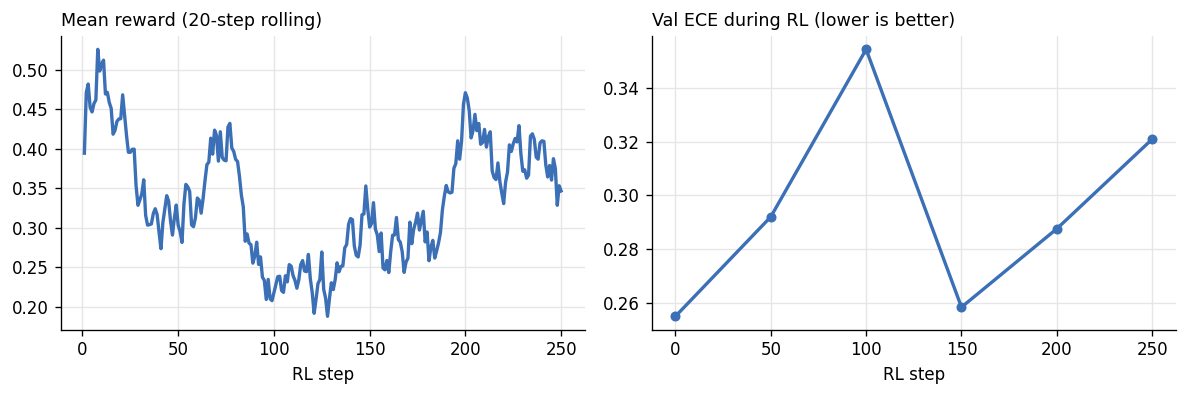

 step  parse   n  agreement  expected_acc  mean_conf   ece  conf_mse
    0    1.0 200      0.770         0.624      0.879 0.255     0.133
   50    1.0 200      0.780         0.636      0.929 0.292     0.155
  100    1.0 200      0.770         0.632      0.987 0.354     0.204
  150    1.0 200      0.765         0.634      0.892 0.258     0.134
  200    1.0 200      0.785         0.639      0.927 0.288     0.151
  250    1.0 200      0.770         0.640      0.961 0.321     0.178


In [15]:
lg = pd.DataFrame(log)
vl = pd.DataFrame(val_log)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), dpi=120)
axes[0].plot(lg["step"], lg["reward"].rolling(20, min_periods=1).mean(), color="#3b6fb6", lw=2)
axes[0].set_title("Mean reward (20-step rolling)", fontsize=10.5, loc="left"); axes[0].set_xlabel("RL step")
axes[1].plot(vl["step"], vl["ece"], color="#3b6fb6", lw=2, marker="o", ms=5)
axes[1].set_title("Val ECE during RL (lower is better)", fontsize=10.5, loc="left"); axes[1].set_xlabel("RL step")
for ax in axes:
    ax.grid(color="#e6e6e6", lw=0.8); ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
fig.tight_layout(); fig.savefig(f"{SAVE_DIR}/rl_curves_v3.png"); plt.show()
print(vl.round(3).to_string(index=False))

# Final exam: v1 → warm-up → v3, with v2 as the upper bound

All four are scored the same way: the model's top answer and its confidence in it, compared with Jev's probability for that answer. For v1 and v2, "confidence" is the internal probability; for the warm-up and v3, it's the **written** number. **ECE is directly comparable** to the earlier notebooks.

`conf_mse` = average (stated confidence − Jev's probability for that answer)². Lower is better; it's the Brier-style error on the confidence itself.

In [16]:
s_v3, ok_v3, texts_v3 = eval_v3(model, eval_ids, eval_ks, targets_eval)
both = np.flatnonzero(ok_v3 & ok_warm)
print(f"Parse rate: warm-up {ok_warm.mean():.3f} | v3 {ok_v3.mean():.3f} | rows parsed by both: {len(both)}")

s_v1 = stats_from_dists([np.asarray(p) for p in preds_v1["v1_pred"]], targets_eval)
s_v2 = stats_from_dists([np.asarray(p) for p in preds_v2["v2_pred"]], targets_eval)
S = {"v1": s_v1, "v3-warmup": s_warm, "v3 (RL)": s_v3, "v2 (upper bound)": s_v2}
table, bins = [], {}
for name, s in S.items():
    m, b = conf_metrics(subset(s, both))
    table.append({"version": name, **m}); bins[name] = b
table = pd.DataFrame(table)
print(table.round(3).to_string(index=False))

Parse rate: warm-up 1.000 | v3 0.999 | rows parsed by both: 1996
         version    n  agreement  expected_acc  mean_conf   ece  conf_mse
              v1 1996      0.788         0.629      0.776 0.148     0.064
       v3-warmup 1996      0.759         0.614      0.867 0.253     0.118
         v3 (RL) 1996      0.755         0.612      0.953 0.342     0.180
v2 (upper bound) 1996      0.774         0.624      0.625 0.005     0.033


In [17]:
print("Per kind (v3):")
pk = []
for kind in sorted(eval_s["kind"].unique()):
    idx = np.intersect1d(both, np.flatnonzero(eval_s["kind"].to_numpy() == kind))
    m, _ = conf_metrics(subset(s_v3, idx))
    pk.append({"kind": kind, **m})
print(pd.DataFrame(pk).round(3).to_string(index=False))
print("\nSample v3 replies:", texts_v3[:10])

Per kind (v3):
  kind   n  agreement  expected_acc  mean_conf   ece  conf_mse
choice 660      0.723         0.605      0.968 0.364     0.215
  noul 723      0.870         0.734      0.997 0.263     0.117
 score 613      0.653         0.475      0.886 0.411     0.218

Sample v3 replies: ['A 99', 'B 100', 'B 99', 'B 99', 'B 100', 'A 100', 'D 99', 'E 99', 'B 99', 'D 65']


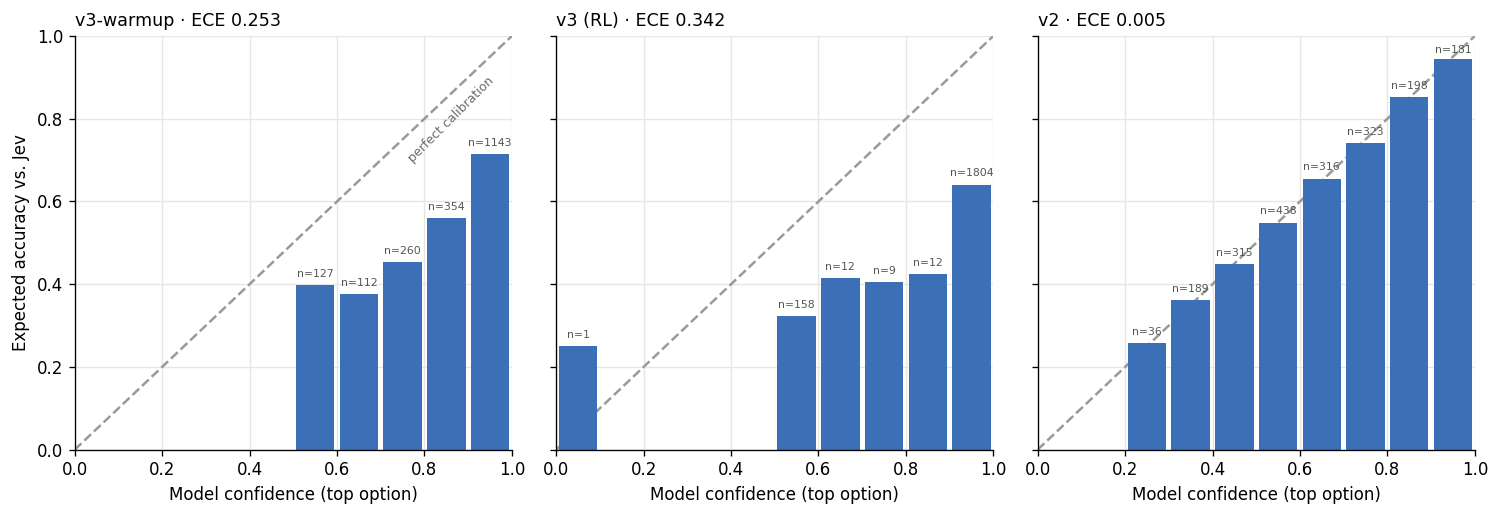

In [18]:
fig = reliability_panels([(f"v3-warmup · ECE {table.loc[1, 'ece']:.3f}", bins["v3-warmup"]),
                          (f"v3 (RL) · ECE {table.loc[2, 'ece']:.3f}", bins["v3 (RL)"]),
                          (f"v2 · ECE {table.loc[3, 'ece']:.3f}", bins["v2 (upper bound)"])],
                         f"{SAVE_DIR}/reliability_v3.png")
plt.show()

## Is RL's effect real? (paired bootstrap, 95% intervals)
`diff` = second minus first. For agreement, positive is better; for ECE and conf_mse, **negative is better**.

In [19]:
sw, s3, s2 = subset(s_warm, both), subset(s_v3, both), subset(s_v2, both)
print("v3 vs warm-up  (what RL itself changed)")
print(bootstrap_conf(sw, s3).round(4).to_string(index=False))
print("\nv3 vs v2  (outcomes-only RL vs full-probability distillation)")
print(bootstrap_conf(s2, s3).round(4).to_string(index=False))

v3 vs warm-up  (what RL itself changed)
   metric    diff  ci_low  ci_high              real?
agreement -0.0045 -0.0170   0.0075 no (could be luck)
      ece  0.0886  0.0812   0.0959                yes
 conf_mse  0.0623  0.0553   0.0694                yes

v3 vs v2  (outcomes-only RL vs full-probability distillation)
   metric    diff  ci_low  ci_high real?
agreement -0.0195 -0.0361  -0.0020   yes
      ece  0.3373  0.3204   0.3440   yes
 conf_mse  0.1472  0.1388   0.1559   yes


In [20]:
now = datetime.datetime.now().isoformat(timespec="minutes")
res_path = f"{SAVE_DIR}/results.csv"
results = pd.read_csv(res_path)
m_w = table.set_index("version").loc["v3-warmup"].to_dict()
m_3 = table.set_index("version").loc["v3 (RL)"].to_dict()
new = pd.DataFrame([
    {"version": "v3-warmup", "model": MODEL_ID, "method": f"v1 + format warm-up on own confidence, {N_WARM} rows",
     **m_w, "parse_rate": float(ok_warm.mean()), "run_at": now},
    {"version": "v3", "model": MODEL_ID, "method": f"GRPO, reward=correct+Brier vs sampled outcome, {len(rl_rows)} prompts x {G}, lr={RL_LR}",
     **m_3, "parse_rate": float(ok_v3.mean()), "run_at": now},
])
results = pd.concat([results[~results["version"].isin(new["version"])], new], ignore_index=True)
results.to_csv(res_path, index=False)
pd.DataFrame({"id": eval_s["id"], "text": texts_v3, "ok": ok_v3}).to_parquet(f"{SAVE_DIR}/preds_v3.parquet")
model.save_pretrained(f"{SAVE_DIR}/v3_adapter")
cols = [c for c in ["version", "agreement", "expected_acc", "mean_conf", "ece", "kl", "brier", "conf_mse", "parse_rate"] if c in results]
print(results[cols].round(3).to_string(index=False))

  version  agreement  expected_acc  mean_conf   ece    kl  brier  conf_mse  parse_rate
       v0      0.349         0.341      0.930 0.590 5.025  0.821       NaN         NaN
    prior      0.399         0.387      0.415 0.028 0.493  0.255       NaN         NaN
       v1      0.788         0.629      0.776 0.148 0.319  0.126       NaN         NaN
    v1+TS      0.788         0.629      0.637 0.028 0.177  0.088       NaN         NaN
       v2      0.774         0.624      0.625 0.005 0.144  0.077       NaN         NaN
    v2+TS      0.774         0.624      0.625 0.005 0.144  0.077       NaN         NaN
v3-warmup      0.759         0.614      0.867 0.253   NaN    NaN     0.118       1.000
       v3      0.755         0.612      0.953 0.342   NaN    NaN     0.180       0.999
